# Modelagem
### 0. Imports e leitura do dataset

In [122]:
from pathlib import Path

import pandas as pd
import numpy as np
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    cross_validate, GridSearchCV
)
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42

In [123]:
df = pd.read_csv('../data/processed/df_02.csv')
print(df.shape)
df.head()

(12530, 2)


,frase,rotulo
0,Ainda estou esperando pelo meu cartão?,chegada_do_cartão
1,O que posso fazer se meu cartão ainda não cheg...,chegada_do_cartão
2,Eu tenho esperado por mais de uma semana. O ca...,chegada_do_cartão
3,Posso rastrear meu cartão enquanto está em pro...,chegada_do_cartão
4,"Como eu posso saber se vou receber meu cartão,...",chegada_do_cartão


### 1. Divisão treino e teste
Divisão estratificada pelo `rotulo` (80% treino / 20% teste), para os dois conjuntos manterem a mesma proporção de cada classe.

In [124]:
X = df['frase']
y = df['rotulo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f'Treino: {X_train.shape[0]} frases')
print(f'Teste: {X_test.shape[0]} frases')

Treino: 10024 frases
Teste: 2506 frases


In [125]:
# Conferindo se a proporção de cada rótulo se manteve nos dois conjuntos
proporcoes = pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'treino': y_train.value_counts(normalize=True),
    'teste': y_test.value_counts(normalize=True),
}).round(4)

print(f"Rótulos no treino: {y_train.nunique()} | no teste: {y_test.nunique()}")
proporcoes.head(10)

Rótulos no treino: 77 | no teste: 77


,total,treino,teste
rotulo,,,
aceitação_de_cartão,0.0075,0.0075,0.0076
alterar_pin,0.0125,0.0125,0.0124
apple_pay_ou_google_pay,0.0126,0.0126,0.0128
ativar_meu_cartão,0.0148,0.0149,0.0148
beneficiário_não_permitido,0.0152,0.0153,0.0152
cancelar_transferência,0.0152,0.0152,0.0152
cartão_comprometido,0.0100,0.0100,0.0100
cartão_engolido,0.0076,0.0076,0.0076
cartão_não_funcionando,0.0109,0.0110,0.0108


### 2. Representações do texto
Para a modelagem, além de usar a representação `TF-IDF` das frases para alguns modelos, usarei a representação em `Embeddings`:

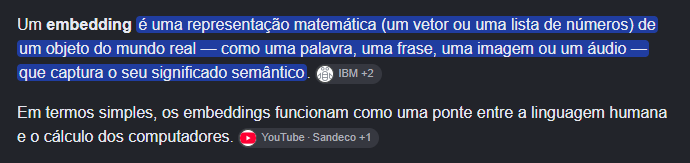

Esses vetores são construídos de modo que textos com significados parecidos fiquem próximos no espaço vetorial, mesmo quando usam palavras diferentes. Neste caso, usarei embeddings de frases, em que o modelo lê a frase inteira e gera um único vetor para ela, levando em conta o contexto e a ordem das palavras. Diferente do TF-IDF, que depende da contagem de termos, essa representação capta relações semânticas, como sinônimos e paráfrases. Isso permite que classificadores simples, como a regressão logística, separem as intenções com base no significado das frases.

**Conjuntos utilizados**

| Representação | Tipo                                    | O que a comparação isola |
|---|-----------------------------------------|---|
| TF-IDF com stopwords | esparsa                                 | efeito de remover stopwords (vs. sem) |
| TF-IDF sem stopwords | esparsa                                 | |
| Serafim 335m | embedding, em português | português vs. multilíngue (vs. e5) |
| multilingual-e5-base | embedding, multilíngue                  | baseline de tamanho para o e5-large |
| multilingual-e5-large | embedding, multilíngue                  | efeito do tamanho do modelo (vs. e5-base) |

#### 2.1 TF-IDF com e sem stopwords
A lista de stopwords é a mesma do notebook 2, sem as negações (`não`, `nem`, `sem`), pois elas podem inverter o sentido das frases.

o TF-IDF é aprendido no treino e apenas aplicados no teste, para não haver data leakage.

In [126]:
nltk.download('stopwords', quiet=True)

negacoes = {'não', 'nem', 'sem'}
stop_pt = set(stopwords.words('portuguese')) - negacoes

In [127]:
# token_pattern mantém palavras de 1 caractere (o, a, é, 1), como no notebook 2
tfidf_com_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')
X_train_tfidf = tfidf_com_stopw.fit_transform(X_train)
X_test_tfidf = tfidf_com_stopw.transform(X_test)

tfidf_sem_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b', stop_words=sorted(stop_pt))
X_train_tfidf_sem_stopw = tfidf_sem_stopw.fit_transform(X_train)
X_test_tfidf_sem_stopw = tfidf_sem_stopw.transform(X_test)

print('Vocabulário com stopwords:', len(tfidf_com_stopw.vocabulary_))
print('Vocabulário sem stopwords:', len(tfidf_sem_stopw.vocabulary_))

Vocabulário com stopwords: 3097
Vocabulário sem stopwords: 2966


#### 2.2 Embeddings
Os modelos codificadores de embeddings que vou usar são:
- **Serafim 335m**: modelo treinado em português. Não usa prefixo nas frases.
- **multilingual-e5-base** e **multilingual-e5-large**: modelos multilingue. Ambos recebem o prefixo `"query: "` nas frases, pois esses modelos foram treinados com prefixos que indicam o papel de cada texto (`"query: "` para perguntas e `"passage: "` para documentos). Assim, os autores recomendam usar `"query: "` em todas as frases em tarefas de classificação.

Usarei as frases sem remover stopwords, pois esses modelos foram treinados com texto natural. Os vetores são normalizados (norma 1).

Como gerar os embeddings demora muito, vou salvá-los em `data/embeddings/` com os índices do treino e do teste. Se a divisão mudar (outro `random_state`, por exemplo), os embeddings são gerados de novo.

In [128]:
MODELOS_EMBEDDING = {
    'serafim_335m': {'nome': 'PORTULAN/serafim-335m-portuguese-pt-sentence-encoder', 'prefixo': ''},
    'e5_base': {'nome': 'intfloat/multilingual-e5-base', 'prefixo': 'query: '},
    'e5_large': {'nome': 'intfloat/multilingual-e5-large', 'prefixo': 'query: '},
}

PASTA_EMBEDDINGS = Path('../data/embeddings')
PASTA_EMBEDDINGS.mkdir(parents=True, exist_ok=True)

In [129]:
# Gera os embeddings de treino e teste de um modelo, ou carrega do disco se já existirem para a mesma divisão
def gerar_embeddings(chave, nome, prefixo, batch_size=32):
    arquivo = PASTA_EMBEDDINGS / f'{chave}.npz'

    if arquivo.exists():
        salvo = np.load(arquivo)
        mesma_divisao = (np.array_equal(salvo['idx_train'], X_train.index.values)
                         and np.array_equal(salvo['idx_test'], X_test.index.values))
        if mesma_divisao:
            print(f'{chave}: carregado de {arquivo}')
            return salvo['train'], salvo['test']
        print(f'{chave}: divisão diferente da salva, gerando de novo')

    modelo = SentenceTransformer(nome)
    def codificar(frases):
        return modelo.encode([prefixo + f for f in frases], batch_size=batch_size,
                             normalize_embeddings=True, show_progress_bar=True)

    emb_train = codificar(X_train)
    emb_test = codificar(X_test)

    np.savez(arquivo, train=emb_train, test=emb_test,
             idx_train=X_train.index.values, idx_test=X_test.index.values)
    print(f'{chave}: salvo em {arquivo}')
    return emb_train, emb_test

In [130]:
embeddings = {}
for chave, config in MODELOS_EMBEDDING.items():
    embeddings[chave] = gerar_embeddings(chave, config['nome'], config['prefixo'])

serafim_335m: carregado de ..\data\embeddings\serafim_335m.npz
e5_base: carregado de ..\data\embeddings\e5_base.npz
e5_large: carregado de ..\data\embeddings\e5_large.npz


#### 2.3 Conjunto de representações
Coloco todas as representações num único dicionário `{nome do conjunto : (X_train, X_test),}`

In [131]:
representacoes = {
    'tfidf_com_stopwords': (X_train_tfidf, X_test_tfidf),
    'tfidf_sem_stopwords': (X_train_tfidf_sem_stopw, X_test_tfidf_sem_stopw),
    **embeddings,
}

pd.DataFrame(
    [(nome, tr.shape[0], te.shape[0], tr.shape[1]) for nome, (tr, te) in representacoes.items()],
    columns=['representação', 'frases treino', 'frases teste', 'dimensões'],
)

,representação,frases treino,frases teste,dimensões
0,tfidf_com_stopwords,10024,2506,3097
1,tfidf_sem_stopwords,10024,2506,2966
2,serafim_335m,10024,2506,1024
3,e5_base,10024,2506,768
4,e5_large,10024,2506,1024


### 3. Baseline: TF-IDF + Regressão Logística sem ajuste
Crio um modelo baseline que será o ponto de referência para comparação de performance dos próximos modelos. Escolhi que esse baseline será a **`Regressão Logística sem ajuste de hiperparâmetros + TF-IDF com stopwords`**.

#### 3.1 Tabela de resultados
Utilizei IA para me ajudar na lógica da organização dos resultados dos modelos, criando uma função reutilizável de registro da performance de cada um deles.

Todos os modelos avaliados são registrados nessa tabela, com o baseline como referência. A coluna `ganho_f1_pp` mostra o ganho de cada modelo em pontos percentuais de F1-macro sobre o baseline.

In [132]:
BASELINE = ('Regressão Logística (baseline)', 'TF-IDF com stopwords')

resultados = {}

# Registra (ou substitui) o resultado de um modelo no teste
def registrar_resultado(modelo, representacao, y_true, y_pred):
    resultados[(modelo, representacao)] = {
        'modelo': modelo,
        'representação': representacao,
        'acurácia': accuracy_score(y_true, y_pred),
        'f1_macro': f1_score(y_true, y_pred, average='macro'),
    }

# Monta a tabela ordenada por F1-macro, com o ganho de cada modelo sobre o baseline
def tabela_resultados():
    tabela = pd.DataFrame(resultados.values())
    f1_baseline = resultados[BASELINE]['f1_macro']
    tabela['ganho_f1_pp'] = (tabela['f1_macro'] - f1_baseline) * 100
    return (tabela.sort_values('f1_macro', ascending=False)
                  .reset_index(drop=True)
                  .round({'acurácia': 4, 'f1_macro': 4, 'ganho_f1_pp': 2}))

#### 3.2 Treino e avaliação

In [133]:
baseline_log_reg = LogisticRegression(max_iter=1000, C=1)
baseline_log_reg.fit(X_train_tfidf, y_train)
y_pred_baseline = baseline_log_reg.predict(X_test_tfidf)

print('Iterações até convergir:', baseline_log_reg.n_iter_[0])

Iterações até convergir: 36


In [134]:
registrar_resultado(*BASELINE, y_test, y_pred_baseline)
tabela_resultados()

,modelo,representação,acurácia,f1_macro,ganho_f1_pp
0,Regressão Logística (baseline),TF-IDF com stopwords,0.8671,0.8654,0.0


### 4. TF-IDF


#### 4.1 TF-IDF com stopwords + Regressão Logística com ajuste

In [135]:
REGLOG_TFIDF = ('Regressão Logística ajustada', 'TF-DF com stopwords')

In [136]:
pipeline_reglog_tfidf = make_pipeline(tfidf_com_stopw, LogisticRegression(max_iter=1000))

grade = {
    'logisticregression__C': [0.1, 1, 10, 100],
    'logisticregression__class_weight': [None, 'balanced'],
}

cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busca_reglog_tfidf = GridSearchCV(
    pipeline_reglog_tfidf,
    param_grid=grade,
    cv=cv_estratificado,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
    refit='f1_macro',
    n_jobs=-1,
)

busca_reglog_tfidf.fit(X_train, y_train)

print('Melhores parâmetros:', busca_reglog_tfidf.best_params_)
print('Melhor F1-macro na validação cruzada:', round(busca_reglog_tfidf.best_score_, 4))

C:\Users\PICHAU\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Melhores parâmetros: {'logisticregression__C': 10, 'logisticregression__class_weight': 'balanced'}
Melhor F1-macro na validação cruzada: 0.8736


In [137]:
y_pred_reglog_tfidf = busca_reglog_tfidf.predict(X_test)

registrar_resultado(*REGLOG_TFIDF, y_test, y_pred_reglog_tfidf)
tabela_resultados()

,modelo,representação,acurácia,f1_macro,ganho_f1_pp
0,Regressão Logística ajustada,TF-DF com stopwords,0.8899,0.8892,2.37
1,Regressão Logística (baseline),TF-IDF com stopwords,0.8671,0.8654,0.00


#### 4.2 TF-IDF sem stopwords + Regressão Logística com ajuste

In [138]:
REGLOG_TFIDF_SSTOPWORDS = ('Regressão Logística ajustada', 'TF-IDF sem stopwords')

In [140]:
pipeline_reglog_tfidf_sstopwords = make_pipeline(tfidf_sem_stopw, LogisticRegression(max_iter=1000))

busca_reglog_tfidf_sstopwords = GridSearchCV(
    pipeline_reglog_tfidf_sstopwords,
    param_grid=grade,
    cv=cv_estratificado,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
    refit='f1_macro',
    n_jobs=-1,
)

busca_reglog_tfidf_sstopwords.fit(X_train, y_train)

print('Melhores parâmetros:', busca_reglog_tfidf_sstopwords.best_params_)
print('Melhor F1-macro na validação cruzada:', round(busca_reglog_tfidf_sstopwords.best_score_, 4))

Melhores parâmetros: {'logisticregression__C': 10, 'logisticregression__class_weight': 'balanced'}
Melhor F1-macro na validação cruzada: 0.8604


In [141]:
y_pred_reglog_tfidf_sstopwords = busca_reglog_tfidf_sstopwords.predict(X_test)

registrar_resultado(*REGLOG_TFIDF_SSTOPWORDS, y_test, y_pred_reglog_tfidf_sstopwords)
tabela_resultados()

,modelo,representação,acurácia,f1_macro,ganho_f1_pp
0,Regressão Logística ajustada,TF-DF com stopwords,0.8899,0.8892,2.37
1,Regressão Logística ajustada,TF-DF sem stopwords,0.8783,0.8761,1.07
2,Regressão Logística (baseline),TF-IDF com stopwords,0.8671,0.8654,0.00


#### 4.3 TF-IDF + LinearSVC